# Edge detector comparison
### Compare Sobel magnitude with Canny at threshold pairs (50, 150), (100, 200) and (150, 250).

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray=cv2.imread('pic.jpg',0)
blur=cv2.GaussianBlur(gray,(5,5),0)


In [ ]:
sx=cv2.Sobel(blur,cv2.CV_64F,1,0,ksize=3)
sy=cv2.Sobel(blur,cv2.CV_64F,0,1,ksize=3)

magntuide=np.sqrt(sx**2+sy**2)

sobel=cv2.convertScaleAbs(magntuide)

_,sobel_edge=cv2.threshold(
    sobel,100,255,cv2.THRESH_BINARY)

In [4]:
canny1=cv2.Canny(blur,50,150)
canny2=cv2.Canny(blur,100,200)
canny3=cv2.Canny(blur,150,250)


In [5]:
results=[('sobel edge',sobel_edge),
('canny(50,150)',canny1),
('canny(100,200)',canny2),
('canny(150,250)',canny3),
]

for name,edge in results:
    print(name,'edge count->',np.count_nonzero(edge))

sobel edge edge count-> 36813
canny(50,150) edge count-> 25242
canny(100,200) edge count-> 14545
canny(150,250) edge count-> 9294


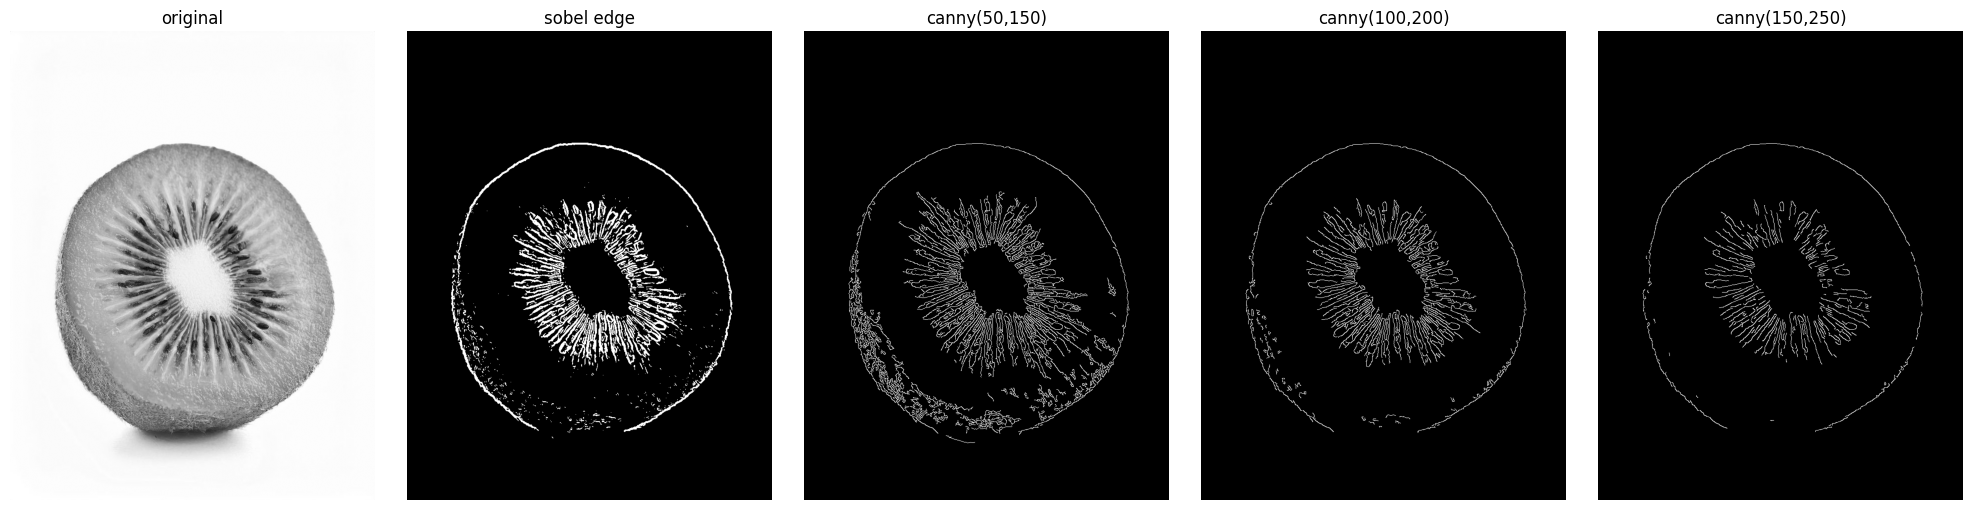

In [6]:
fig,axes=plt.subplots(1,5,figsize=(20,5))
images=[gray,sobel_edge,canny1,canny2,canny3]
titles=['original','sobel edge','canny(50,150)','canny(100,200)','canny(150,250)']

for ax,img,title in zip(axes,images,titles):
    ax.imshow(img,cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.savefig('29_figure.jpg')
plt.show()